In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler


In [2]:
# Load the datasets
mat_data = pd.read_csv('student-mat.csv', sep=';')
por_data = pd.read_csv('student-por.csv', sep=';')

combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [3]:
# Display basic information about the dataset
print("Shape of the dataset:", combined_data.shape)
print("\nColumn Data Types:")
print(combined_data.dtypes)

Shape of the dataset: (1044, 33)

Column Data Types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [5]:
from sklearn.preprocessing import LabelEncoder

# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])


In [6]:
# Summary statistics
print("\nSummary statistics for numerical features:")
print(combined_data.describe())



Summary statistics for numerical features:
            school          sex          age      address      famsize  \
count  1044.000000  1044.000000  1044.000000  1044.000000  1044.000000   
mean      0.260536     0.433908     0.246579     0.727011     0.293103   
std       0.439138     0.495850     0.177139     0.445708     0.455404   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.000000     0.000000     0.142857     0.000000     0.000000   
50%       0.000000     0.000000     0.285714     1.000000     0.000000   
75%       1.000000     1.000000     0.428571     1.000000     1.000000   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

           Pstatus         Medu         Fedu   traveltime    studytime  ...  \
count  1044.000000  1044.000000  1044.000000  1044.000000  1044.000000  ...   
mean      0.884100     0.650862     0.596983     0.174330     0.323436  ...   
std       0.320259     0.281227     0.274985     0.2

In [7]:
# Check for missing values
print("\nMissing values in the dataset:")
print(combined_data.isnull().sum())


Missing values in the dataset:
school               0
sex                  0
age                  0
address              0
famsize              0
Pstatus              0
Medu                 0
Fedu                 0
traveltime           0
studytime            0
failures             0
schoolsup            0
famsup               0
paid                 0
activities           0
nursery              0
higher               0
internet             0
romantic             0
famrel               0
freetime             0
goout                0
Dalc                 0
Walc                 0
health               0
absences             0
G1                   0
G2                   0
G3                   0
Mjob_health          0
Mjob_other           0
Mjob_services        0
Mjob_teacher         0
Fjob_health          0
Fjob_other           0
Fjob_services        0
Fjob_teacher         0
reason_home          0
reason_other         0
reason_reputation    0
guardian_mother      0
guardian_other       0
dt


Visualizing distributions for numerical features...


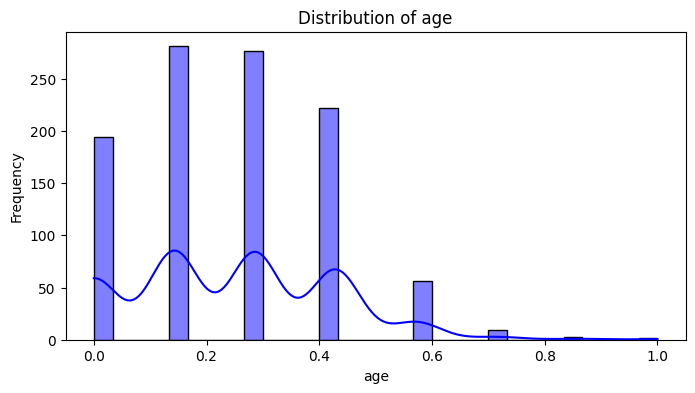

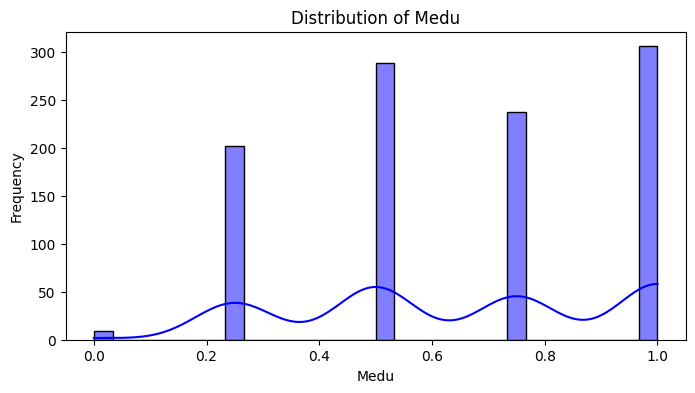

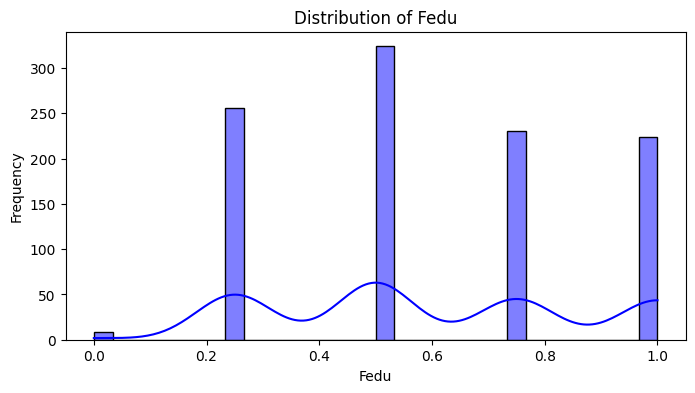

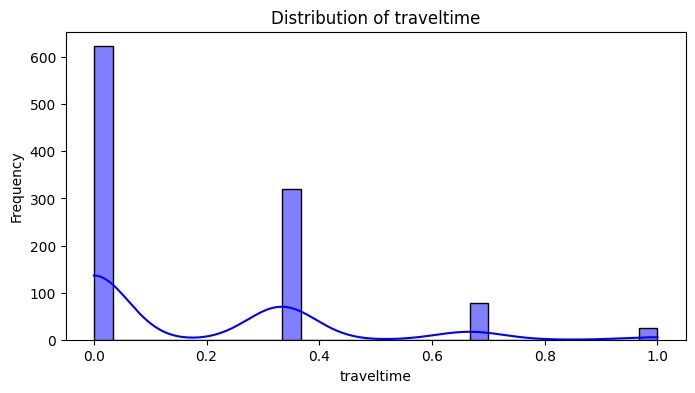

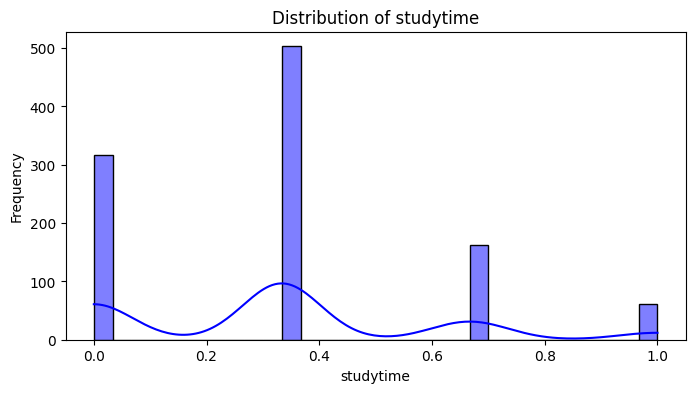

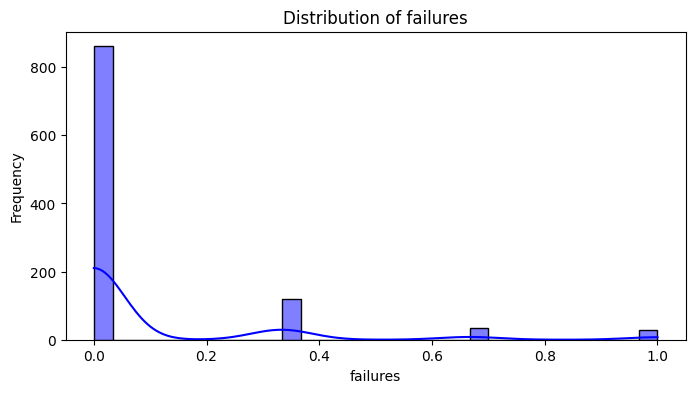

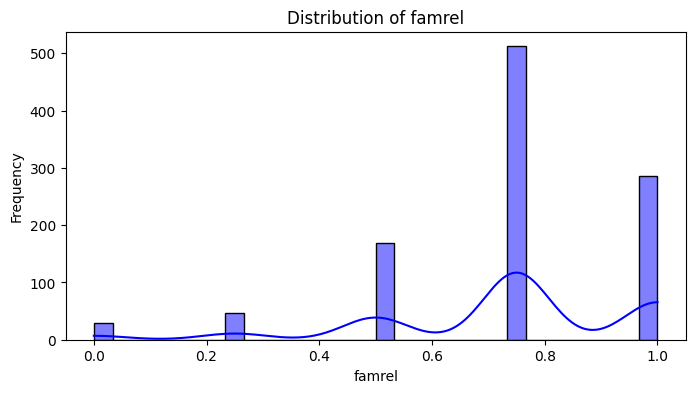

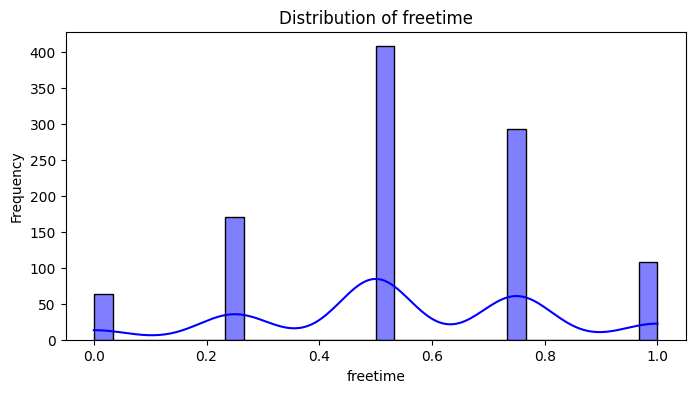

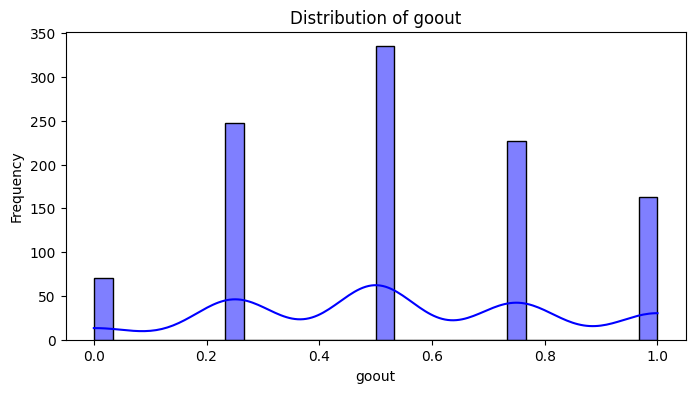

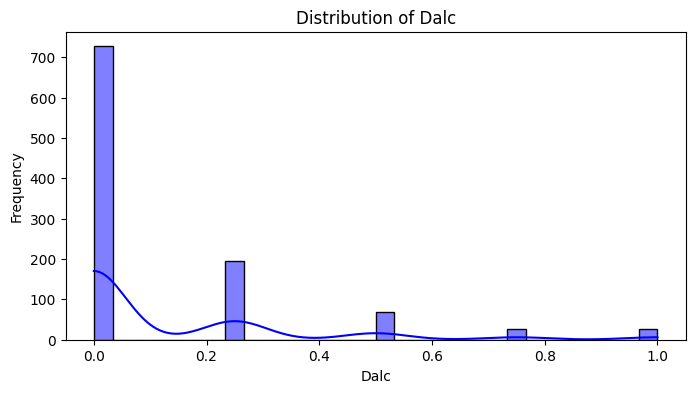

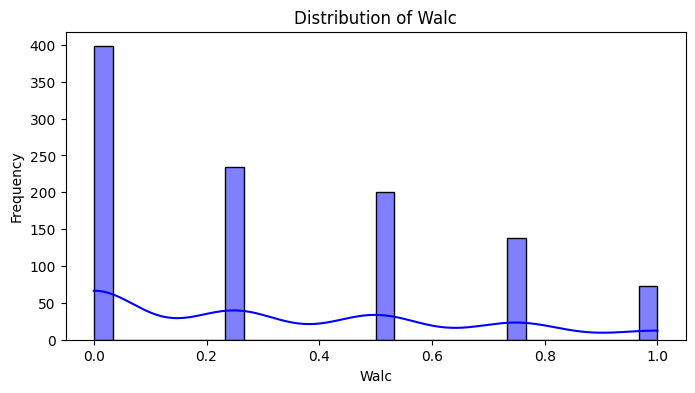

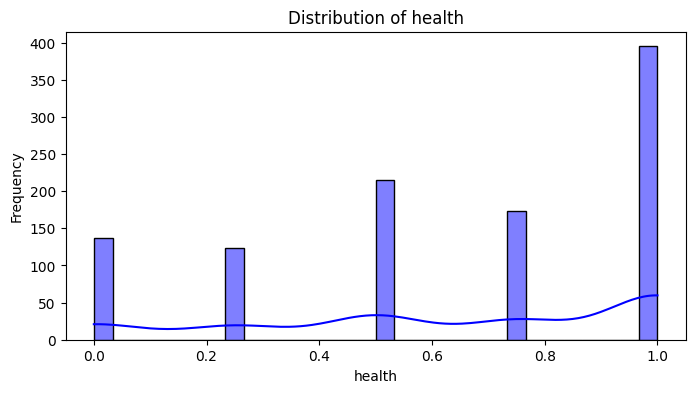

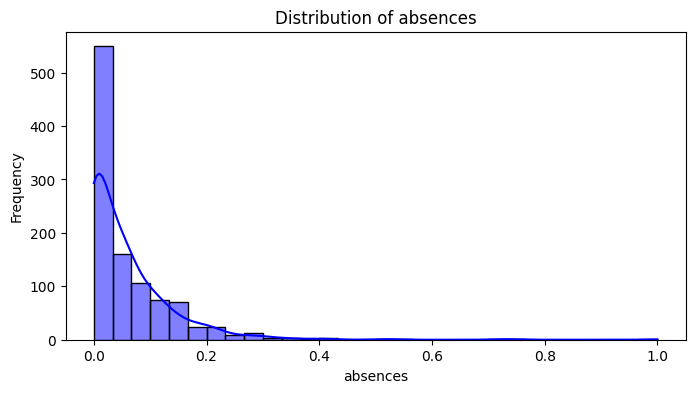

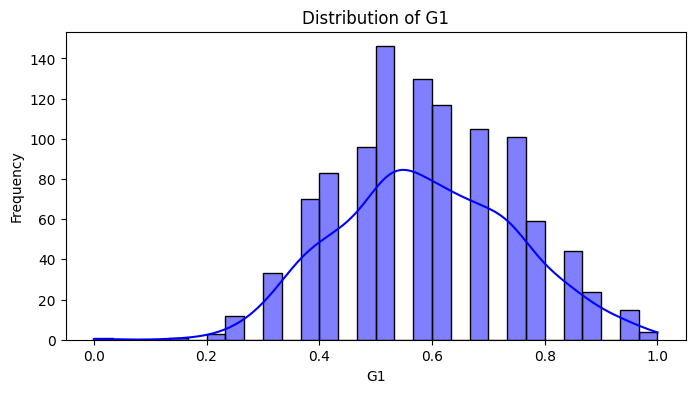

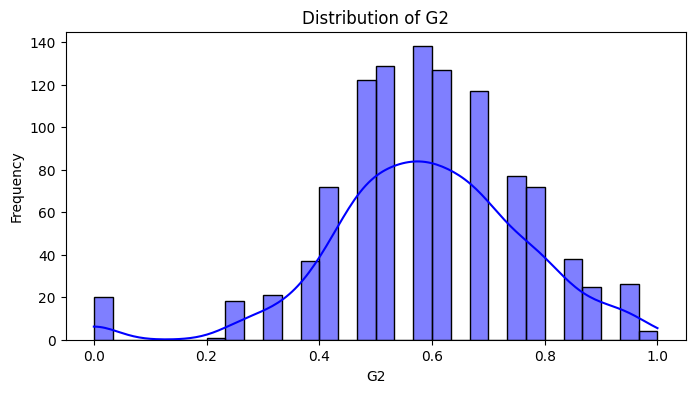

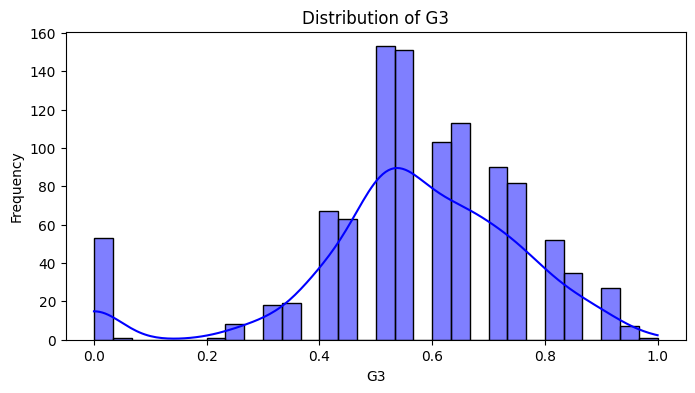

In [8]:
# Visualizing distributions for numerical features
print("\nVisualizing distributions for numerical features...")
for col in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(combined_data[col], kde=True, bins=30, color='blue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()


Checking for outliers...


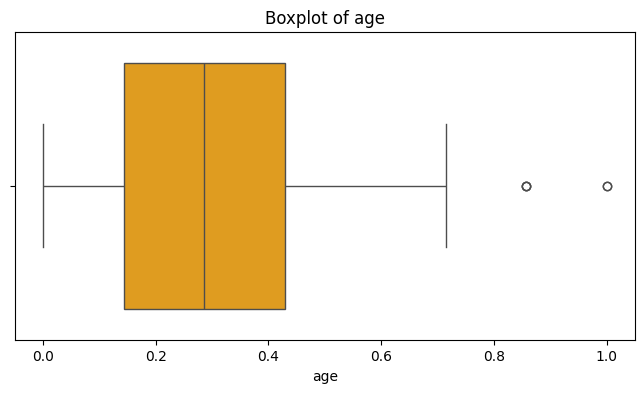

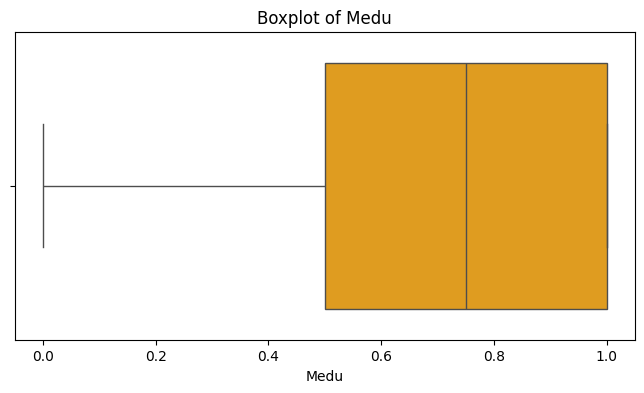

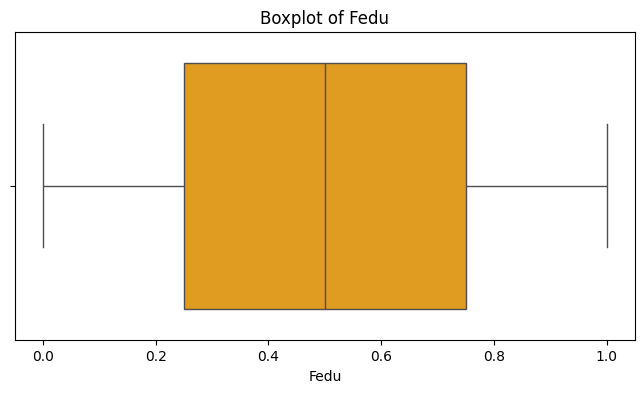

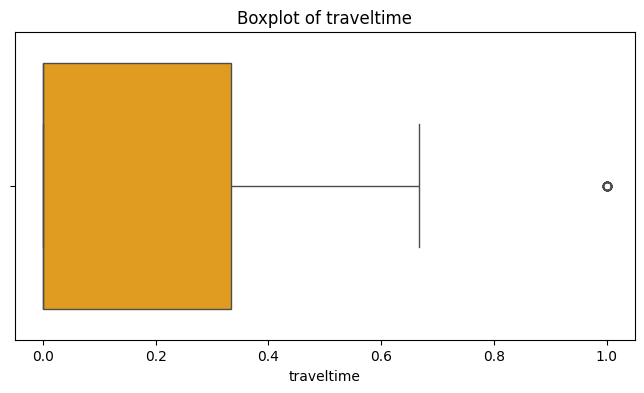

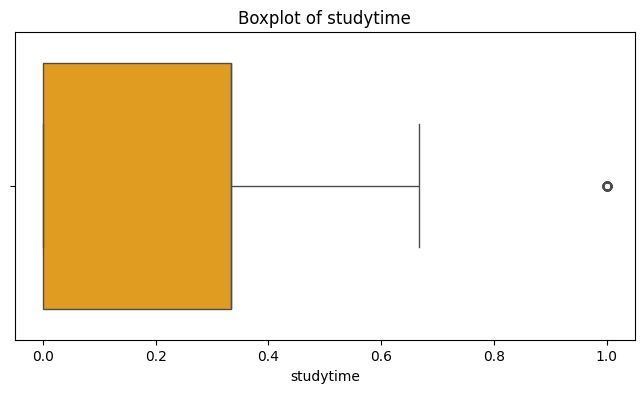

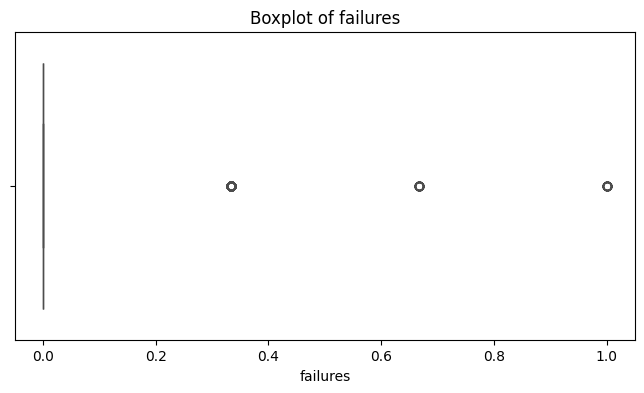

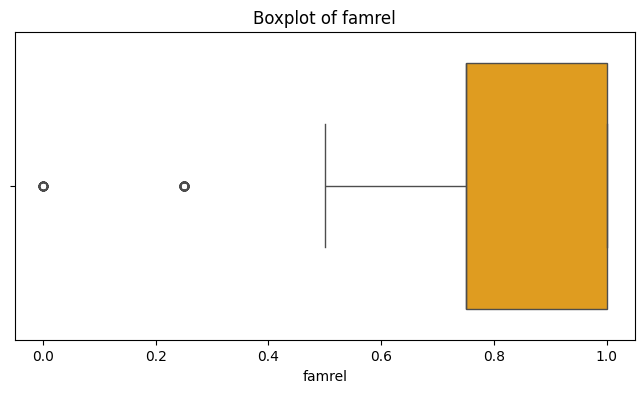

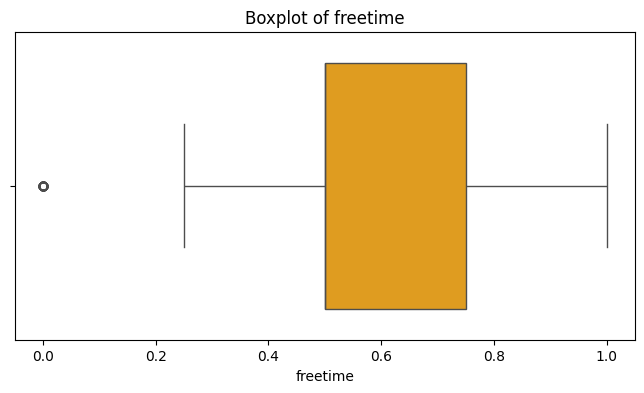

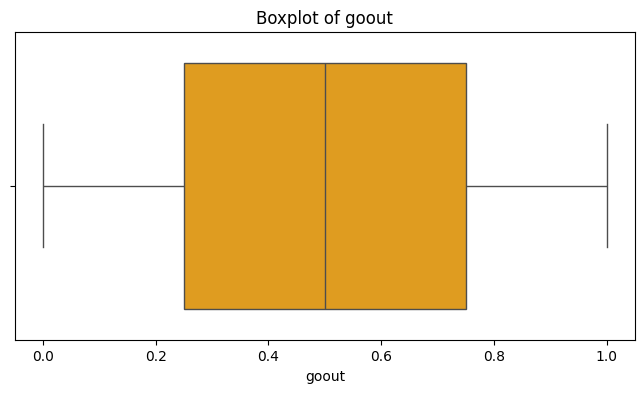

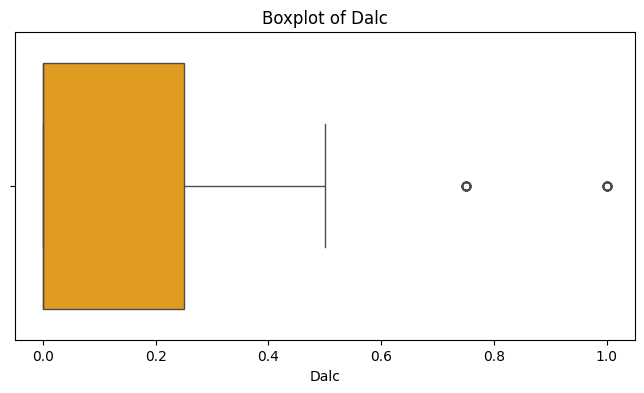

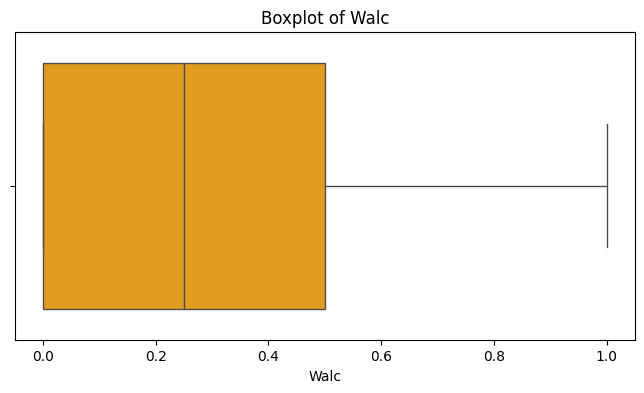

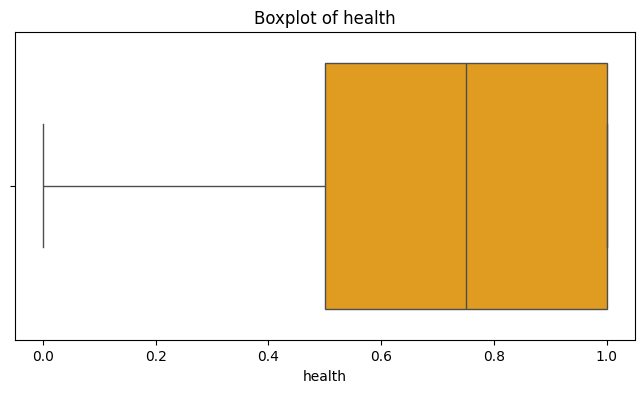

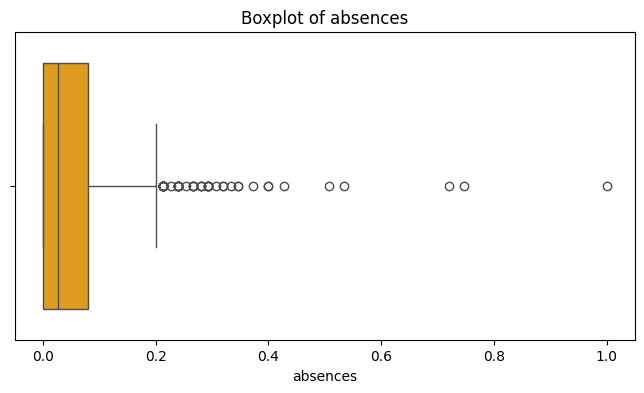

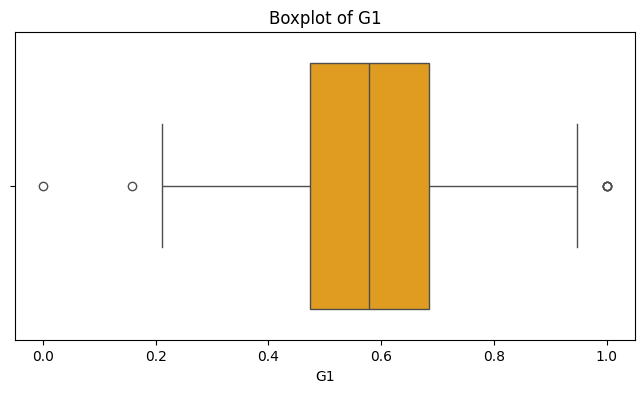

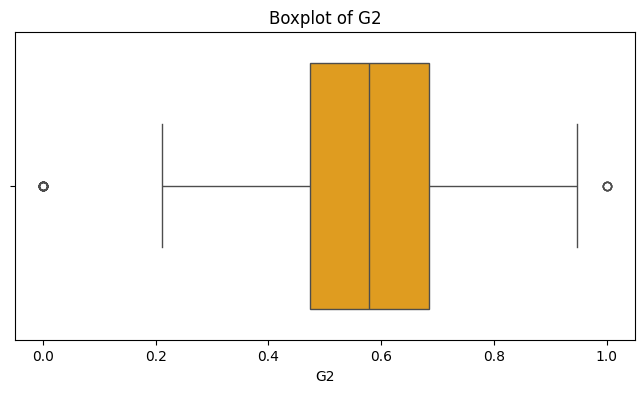

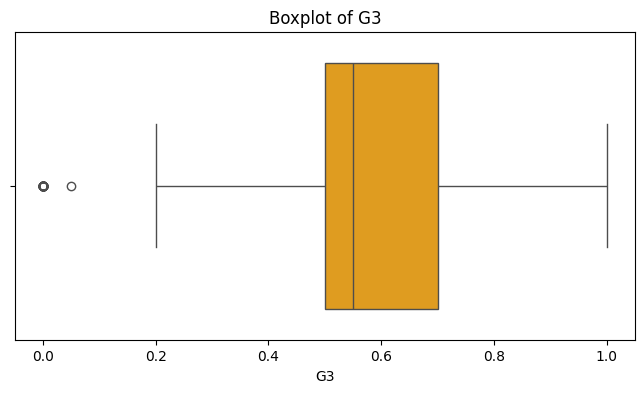

In [9]:
# Checking for outliers using boxplots
print("\nChecking for outliers...")
for col in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=combined_data[col], color='orange')
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

In [10]:
print("\nDetecting outliers using the IQR method...")
outliers = {}
for col in numeric_features:
    # Calculate Q1, Q3, IQR
    Q1 = combined_data[col].quantile(0.25)
    Q3 = combined_data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define the lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Find the outliers
    outliers[col] = combined_data[(combined_data[col] < lower_bound) | (combined_data[col] > upper_bound)]
    
    # Calculate the median for the feature
    median_value = combined_data[col].median()
    
    # Print the results
    print(f"\n{col}:")
    print(f"  - Median value: {median_value}")
    
    # Display the outliers (extreme values)
    if outliers[col].shape[0] > 0:
        print(f"  - Number of outliers: {outliers[col].shape[0]}")
        print(f"  - Outliers:")
        print(outliers[col][col].to_list())
    else:
        print(f"  - No outliers detected.")
    
    # Find the most extreme values (outliers)
    if not outliers[col].empty:
        most_extreme_values = outliers[col].sort_values(by=col, ascending=False).head(1)
        print(f"  - Most extreme outlier value: {most_extreme_values[col].values[0]} at index {most_extreme_values.index[0]}")

# Optional: print a general message about the dataset's status
print("\nOutlier detection completed. Please review the extreme values listed above for each feature.")


Detecting outliers using the IQR method...

age:
  - Median value: 0.2857142857142856
  - Number of outliers: 5
  - Outliers:
[1.0, 0.8571428571428572, 1.0, 0.8571428571428572, 0.8571428571428572]
  - Most extreme outlier value: 1.0 at index 247

Medu:
  - Median value: 0.75
  - No outliers detected.

Fedu:
  - Median value: 0.5
  - No outliers detected.

traveltime:
  - Median value: 0.0
  - Number of outliers: 24
  - Outliers:
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
  - Most extreme outlier value: 1.0 at index 61

studytime:
  - Median value: 0.3333333333333333
  - Number of outliers: 62
  - Outliers:
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1


Correlation matrix:


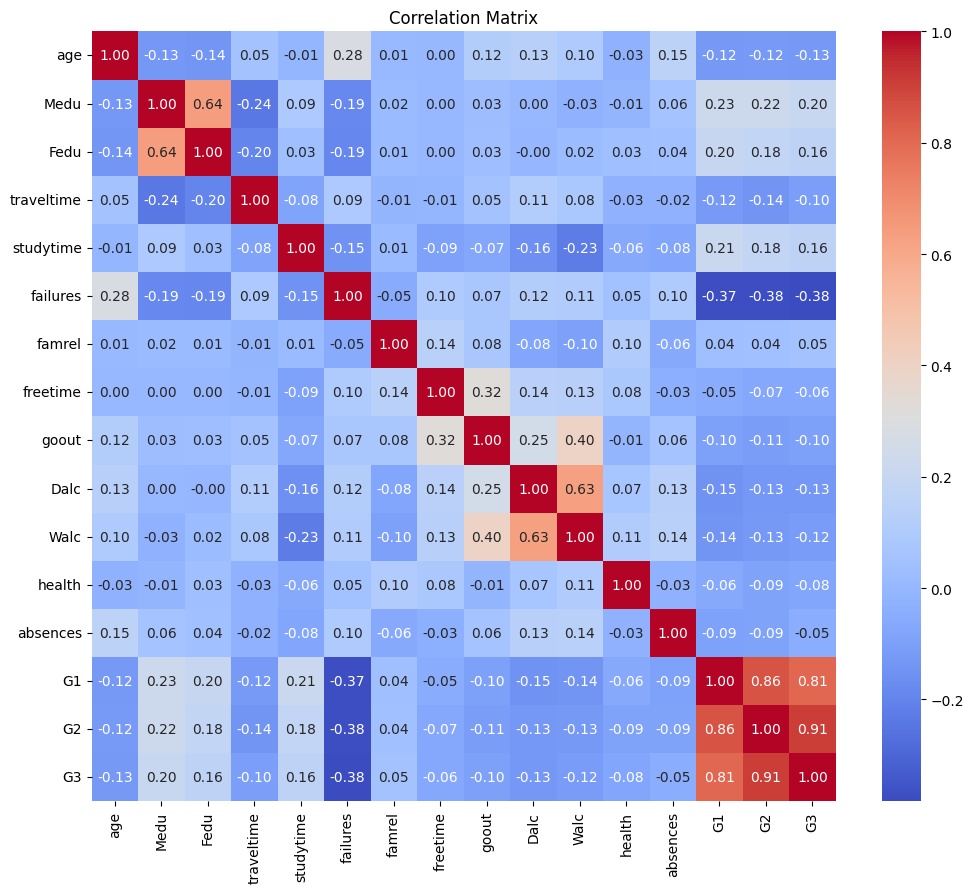

In [11]:
# Correlation matrix to identify highly correlated features
print("\nCorrelation matrix:")
corr_matrix = combined_data[numeric_features].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [12]:
# Identifying unique values and counts for categorical features
print("\nUnique values and counts for binary and one-hot encoded categorical features:")
for col in binary_features + [col for col in combined_data.columns if col.startswith(tuple(categorical_features))]:
    print(f"\n{col}:")
    print(combined_data[col].value_counts())


Unique values and counts for binary and one-hot encoded categorical features:

school:
school
0    772
1    272
Name: count, dtype: int64

sex:
sex
0    591
1    453
Name: count, dtype: int64

address:
address
1    759
0    285
Name: count, dtype: int64

famsize:
famsize
0    738
1    306
Name: count, dtype: int64

Pstatus:
Pstatus
1    923
0    121
Name: count, dtype: int64

schoolsup:
schoolsup
0    925
1    119
Name: count, dtype: int64

famsup:
famsup
1    640
0    404
Name: count, dtype: int64

paid:
paid
0    824
1    220
Name: count, dtype: int64

activities:
activities
0    528
1    516
Name: count, dtype: int64

nursery:
nursery
1    835
0    209
Name: count, dtype: int64

higher:
higher
1    955
0     89
Name: count, dtype: int64

internet:
internet
1    827
0    217
Name: count, dtype: int64

romantic:
romantic
0    673
1    371
Name: count, dtype: int64

Mjob_health:
Mjob_health
False    962
True      82
Name: count, dtype: int64

Mjob_other:
Mjob_other
False    645
True  